<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C31_Notebook-35.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

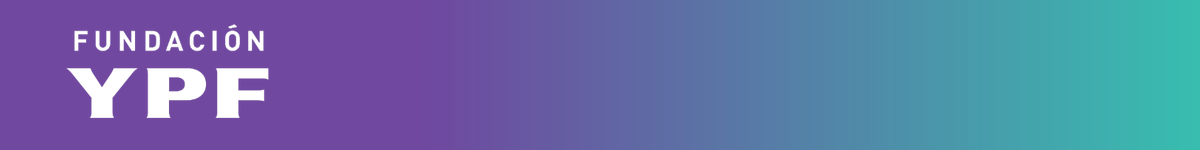

# Fundación YPF - Data Science

## Notebook 35: Cómo armar y documentar un portfolio de Data Science

### Índice de partes

* **Parte 0:** Preparación del entorno y repaso de temas recientes
* **Parte 1:** Qué es un portfolio de Data Science y por qué construirlo
* **Parte 2:** Cómo documentar un proyecto: estructura de repositorio y README
* **Parte 3:** Caso de estudio: documentando un análisis de esperanza de vida
* **Parte 4:** Checklist final para el repositorio de portfolio
* **Parte 5:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno y repaso de temas recientes

Esta clase es distinta a las anteriores del módulo: no presenta un algoritmo nuevo. Es un **espacio práctico** para preparar el portfolio y la entrega final del curso, así que este notebook tampoco enseña una técnica nueva de Machine Learning: funciona como una **plantilla comentada** que muestra, con un caso real, cómo documentar un análisis para que quede listo para mostrar en un repositorio.

**Repaso rápido de las últimas clases:**

* En la Clase 29 vimos cómo poner un modelo en producción: pipelines, repositorios de modelos versionados y contenedores.
* En la Clase 30 vimos cómo monitorear un modelo ya en producción: qué mide el monitoreo, por qué es necesario y qué problemas permite detectar.
* Hoy cerramos el círculo: todo el trabajo hecho a lo largo del curso, desde la limpieza de datos hasta el monitoreo, tiene que poder mostrarse de forma clara y ordenada en un portfolio.

**Dataset usado en este notebook:**

* `life_expectancy_data.csv`: indicadores de esperanza de vida, salud, economía y educación de distintos países entre 2000 y 2015. Es un dataset ya usado en clases anteriores del curso (módulo de regresión); acá lo retomamos como caso de estudio para mostrar, paso a paso, cómo se documenta un análisis pensado para portfolio.

In [ ]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Qué es un portfolio de Data Science y por qué construirlo

Un portfolio es la mejor manera de mostrar las habilidades de programación y de modelado de datos, a través de proyectos concretos que se puedan compartir, leer y revisar.

**Cómo empezar:**

* Elegir temas que generen interés genuino.
* Buscar datos relacionados que se puedan analizar: Kaggle, Google Dataset Search, UCI Machine Learning Repository, portales de datos abiertos de gobiernos y organismos, o un dataset propio armado con web scraping (por ejemplo con Selenium o Scrapy).
* Evitar apoyarse solo en los datasets más conocidos (Titanic, MNIST, Iris): un proyecto con un dataset menos trillado se nota más.
* Sumarse a hackathons y competencias para sumar proyectos y práctica.

**Dónde mostrar el trabajo:**

* GitHub o GitLab, para el código y los notebooks.
* Kaggle, para notebooks y competencias.
* Medium (u otro blog), para artículos que cuenten el proceso con palabras y no solo con código.

**Habilidades que un portfolio debería demostrar:**

* Habilidades de programación.
* Entendimiento de los problemas y búsqueda de respuestas usando datos.
* Conocimiento teórico de cómo funcionan los modelos: selección de hiperparámetros, transformación de datos, manejo de datos faltantes.
* Storytelling y comunicación: describir el trabajo, escribir artículos y contar una historia con los datos.

## Parte 2: Cómo documentar un proyecto: estructura de repositorio y README

Para la entrega final del curso (y para cualquier proyecto de portfolio) el repositorio tiene que incluir:

* **Readme**: un resumen de no más de un párrafo por ítem, contando de dónde se obtuvo el dataset, un resumen del proyecto, qué objetivo se propuso y qué se descubrió en el análisis exploratorio, y el detalle de los modelos ajustados.
* **Dataset**, o instrucciones claras de cómo conseguirlo si pesa demasiado para subirlo al repositorio.
* **Notebook con el análisis exploratorio.**
* **Notebooks donde se apliquen modelos de aprendizaje supervisado y no supervisado**, mostrando los resultados obtenidos.
* Es muy valorado que el repositorio **cuente una historia** con esos datos: qué preguntas se hicieron, qué conclusiones se sacaron y qué decisiones se tomaron a partir de los datos.

Un esquema simple de README, para copiar y adaptar a cualquier proyecto:

```markdown
# Nombre del proyecto

## Objetivo
Qué pregunta se intenta responder y por qué importa.

## Datos
De dónde salen los datos, cuántas filas y columnas tienen, y qué significa cada variable relevante.

## Análisis exploratorio
Principales hallazgos: distribuciones, relaciones entre variables, datos faltantes y cómo se trataron.

## Modelo
Qué modelo o modelos se entrenaron, con qué métricas se evaluaron y qué resultado dieron.

## Conclusiones
Qué se aprendió, qué decisiones se tomarían con esta información y qué quedaría pendiente.
```

A partir de acá aplicamos esta misma estructura sobre un caso real, con `life_expectancy_data.csv`.

## Parte 3: Caso de estudio: documentando un análisis de esperanza de vida

Seguimos el esquema de README de la Parte 2, pero ahora con código real: cargamos los datos, documentamos el objetivo, hacemos el análisis exploratorio, entrenamos un modelo simple y escribimos las conclusiones con los números que salen del propio notebook.

### Objetivo

¿Qué variables de salud, economía y educación están más asociadas a la esperanza de vida de un país, y se puede construir un modelo simple que la prediga razonablemente bien?

In [ ]:
if not os.path.exists("life_expectancy_data.csv"):
    from google.colab import files
    files.upload()

datos = pd.read_csv("life_expectancy_data.csv")
datos.columns = [c.strip() for c in datos.columns]
print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [ ]:
nulos = datos.isna().sum().sort_values(ascending=False)
nulos = nulos[nulos > 0]
print("Columnas con datos faltantes:")
print(nulos)

Columnas con datos faltantes:
Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
thinness 5-9 years                  34
thinness  1-19 years                34
BMI                                 34
Polio                               19
Diphtheria                          19
Life expectancy                     10
Adult Mortality                     10
dtype: int64


In [ ]:
correlaciones = datos.corr(numeric_only=True)["Life expectancy"].sort_values(ascending=False)
correlaciones

Life expectancy                    1.000000
Schooling                          0.751975
Income composition of resources    0.724776
BMI                                0.567694
Diphtheria                         0.479495
Polio                              0.465556
GDP                                0.461455
Alcohol                            0.404877
percentage expenditure             0.381864
Hepatitis B                        0.256762
Total expenditure                  0.218086
Year                               0.170033
Population                        -0.021538
Measles                           -0.157586
infant deaths                     -0.196557
under-five deaths                 -0.222529
thinness 5-9 years                -0.471584
thinness  1-19 years              -0.477183
HIV/AIDS                          -0.556556
Adult Mortality                   -0.696359
Name: Life expectancy, dtype: float64

### Qué encontramos en el análisis exploratorio

* El dataset tiene 2938 filas y 22 columnas. Varias variables tienen datos faltantes, las más afectadas son `Population`, `Hepatitis B` y `GDP`.
* Las variables con mayor correlación positiva con `Life expectancy` son `Schooling` (escolaridad, alrededor de 0.75), `Income composition of resources` (alrededor de 0.72) y `BMI` (alrededor de 0.57).
* Las variables con mayor correlación negativa son `Adult Mortality` (mortalidad adulta, alrededor de -0.70) y `HIV/AIDS` (alrededor de -0.56).
* Esto tiene sentido: a mejor nivel educativo y económico, y a menor mortalidad adulta y prevalencia de HIV/AIDS, mayor esperanza de vida.

Con estos hallazgos, elegimos un subconjunto chico de variables para un primer modelo simple.

### Modelo

Entrenamos una **regresión lineal** (aprendizaje supervisado) usando las variables que más se correlacionan con la esperanza de vida: `Schooling`, `Income composition of resources`, `BMI`, `Adult Mortality` y `HIV/AIDS`. No es el objetivo de esta clase explicar el algoritmo en detalle (eso ya se vio en el módulo de regresión), sino mostrar cómo se documenta la elección de variables, el entrenamiento y la evaluación en un notebook de portfolio.

In [ ]:
features = ["Schooling", "Income composition of resources", "BMI", "Adult Mortality", "HIV/AIDS"]
target = "Life expectancy"

datos_modelo = datos[features + [target]].dropna().reset_index(drop=True)
print("Filas usadas para el modelo:", len(datos_modelo), "de", len(datos), "filas totales")

X = datos_modelo[features]
y = datos_modelo[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

modelo = LinearRegression().fit(X_train, y_train)
predicciones = modelo.predict(X_test)

r2 = r2_score(y_test, predicciones)
mae = mean_absolute_error(y_test, predicciones)
print(f"R2 en test: {r2:.3f}")
print(f"MAE en test: {mae:.2f} años")

Filas usadas para el modelo: 2736 de 2938 filas totales
R2 en test: 0.824
MAE en test: 2.84 años


### Conclusiones

* Con solo 5 variables (escolaridad, composición de ingresos, BMI, mortalidad adulta y HIV/AIDS) la regresión lineal explica alrededor del 82% de la variación de la esperanza de vida en los países de test (R2 cercano a 0.82).
* El error promedio del modelo es de alrededor de 2.8 años, un valor razonable para un primer modelo simple.
* Un README de portfolio para este proyecto resumiría esto en pocas líneas, por ejemplo:

> **Proyecto**: predicción de esperanza de vida por país.
> **Datos**: `life_expectancy_data.csv`, 2938 filas, indicadores de 2000 a 2015 por país.
> **Hallazgo principal**: la escolaridad y la composición de ingresos son las variables más asociadas a la esperanza de vida; la mortalidad adulta y el HIV/AIDS la reducen.
> **Modelo**: regresión lineal con 5 variables, R2 de aproximadamente 0.82 y error promedio de aproximadamente 2.8 años en test.
> **Próximos pasos**: probar modelos no lineales, incorporar más variables tratando los datos faltantes, y analizar el error por región o nivel de desarrollo.

Esto es exactamente lo que se espera encontrar en el README del repositorio de cada proyecto final: pocas líneas, pero que cuenten toda la historia del análisis.

## Parte 4: Checklist final para el repositorio de portfolio

Antes de entregar el link del repositorio, conviene revisar que incluya:

- [ ] Readme con el resumen del proyecto (objetivo, datos, hallazgos del análisis exploratorio y detalle de los modelos).
- [ ] Dataset, o instrucciones claras de cómo conseguirlo.
- [ ] Notebook con el análisis exploratorio de datos.
- [ ] Notebooks con los modelos de aprendizaje supervisado y no supervisado aplicados, mostrando los resultados obtenidos.
- [ ] Una historia clara contada con los datos: preguntas, conclusiones y decisiones tomadas.
- [ ] Código ordenado y comentado, sin celdas sueltas de prueba que no aporten a la historia.
- [ ] Presentación lista (PowerPoint, Slides o Canva) para los 15 minutos de síntesis de la última clase.

## Parte 5: Ejercicio para las salas de Zoom

En los grupos de trabajo ya establecidos:

1. Elijan uno de los datasets que ya usaron en el curso (por ejemplo `blackfriday`, `clientes_mall`, `StudentsPerformance`, `cancer_mamario` o `venta_autos`), o el dataset que estén usando para su proyecto final.
2. Completen, en un documento o en una celda de markdown, el esquema de README de la Parte 2 para ese dataset: objetivo, datos, principales hallazgos del análisis exploratorio, modelo usado y conclusiones.
3. Revisen juntos el checklist de la Parte 4 contra el repositorio que vienen armando para la entrega final y marquen qué falta.
4. Al volver de las salas, cada grupo comparte en un minuto qué le faltaba a su repositorio y qué va a priorizar antes de la entrega final.